In [6]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import truncnorm

In [7]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (8, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')


In [8]:
fs = 15 # tick fontsize
fsL = fs + 3 # Latex fontsize
dpi = 300

In [90]:
kappa_u = 0.1
kappa_i = .9 

k = 1 
zeta = 1

phi_I =phi_B = 0.
alpha_I = 0.
alpha_B = 0.

T = 1
N = 200
dt = T / N
batch_size = 100
nb_steps = 1_000
iter_banach = 50

sigma_a = 5 
eta_a  = .3

eta_ZM = 10
eta_ZP = 10 
sigma_ZP = 1
sigma_ZM = 1 
Z_bound = 0.3

S0 = 100
c = 1
k = k*c
zeta = zeta*c
sigma_ZP = sigma_ZP * c
sigma_ZM = sigma_ZM * c
beta = 1 / (2 * k * (1 - k * kappa_u))
d = (1/(2*kappa_i)/(1+beta/(2*kappa_i))) 
sigma_s = 1

# Condition for the Banach fixed point iteration

In [91]:
print((1 / (2 * kappa_i))<1,beta<1)
print(beta)
print(1-k*beta)
print(1-2*k*kappa_u)
print("condition conv <1", 1-kappa_u*k)

True True
0.5555555555555556
0.4444444444444444
0.8
condition conv <1 0.9


In [92]:
torch.manual_seed(0)

In [93]:
class ZNet(nn.Module):
    def __init__(self, input_dim, output_dim=1, hidden_dim=64):
        super(ZNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )
    def forward(self, t,y_I, y_B, q_I, q_B,z_plus,z_minus,alpha):
        xy = torch.cat([t,y_I, y_B, q_I, q_B,z_plus,z_minus,alpha], dim=1)
        return self.net(xy)

In [94]:
def simulate_trajectory(Q0_I,Q0_B, Y0_I,Y0_B,Z_nets, 
                        b_QI,b_QB,b_YI,b_YB, T, N, dW_S,dW_A,dW_ZP,dW_ZM):
    Q_I,Q_B, Y_I,Y_B, Z_vals_IS,Z_vals_IA,Z_vals_BS,Z_vals_BA,Z_vals_I_plus,Z_vals_I_minus,Z_vals_B_plus,Z_vals_B_minus,alpha,Z_plus,Z_minus=[Q0_I],[Q0_B], [Y0_I],[Y0_B],[],[],[],[],[],[],[],[], [torch.zeros(1, 1).expand(Q0_I.shape[0], -1)],[torch.zeros(1, 1).expand(Q0_I.shape[0], -1)],[torch.zeros(1, 1).expand(Q0_I.shape[0], -1)]

    for i in range(N):

        q_I,q_B, y_I,y_B,Alpha,ZP,ZM = Q_I[-1],Q_B[-1], Y_I[-1],Y_B[-1],alpha[-1],Z_plus[-1],Z_minus[-1]
        t = torch.full(
                    (q_I.shape[0], 1),
                    i * dt / T,
                    dtype=q_I.dtype,
                    device=q_I.device
                )

        z_IS = Z_nets[0](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        z_IA = Z_nets[1](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        z_BS = Z_nets[2](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        z_BA = Z_nets[3](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        z_I_plus = Z_nets[4](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        z_I_minus = Z_nets[5](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        z_B_plus = Z_nets[6](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        z_B_minus = Z_nets[7](t,y_I,y_B,q_I,q_B,ZP,ZM,Alpha)
        
        Z_vals_IS.append(z_IS)
        Z_vals_IA.append(z_IA)
        Z_vals_BS.append(z_BS)
        Z_vals_BA.append(z_BA)
        Z_vals_I_plus.append(z_I_plus)
        Z_vals_I_minus.append(z_I_minus)
        Z_vals_B_plus.append(z_B_plus)
        Z_vals_B_minus.append(z_B_minus)
        
        dWt_S = dW_S[:, i, :]
        dWt_A = dW_A[:, i, :]
        dWt_ZP = dW_ZP[:,i,:]
        dWt_ZM = dW_ZM[:,i,:]
        
        nu_plus,nu_minus,delta_plus,delta_minus = nu(y_I,y_B,ZP,ZM)        
      
        q_I_next = q_I + b_QI(nu_plus,nu_minus) * dt 
        q_B_next = q_B + b_QB(nu_plus,nu_minus,delta_plus,delta_minus,ZP,ZM) * dt
        
        y_I_next = y_I + b_YI(q_I,Alpha) * dt + z_IS * dWt_S + z_IA * dWt_A + z_I_plus*dWt_ZP + z_I_minus*dWt_ZM
        y_B_next = y_B + b_YB(q_B,Alpha) * dt + z_BS * dWt_S + z_BA * dWt_A+ z_B_plus*dWt_ZP + z_B_minus*dWt_ZM
        
        alpha_next = Alpha - eta_a * Alpha * dt + dWt_A*sigma_a
        z_plus_next = ZP - eta_ZP*ZP*dt + dWt_ZP*sigma_ZP
        z_minus_next = ZM - eta_ZM*ZM*dt + dWt_ZM*sigma_ZM
        z_plus_next = torch.clamp(z_plus_next, min=-Z_bound, max=Z_bound)
        z_minus_next = torch.clamp(z_minus_next, min=-Z_bound, max=Z_bound)

        
        Z_plus.append(z_plus_next)
        Z_minus.append(z_minus_next)
        alpha.append(alpha_next)
        Q_I.append(q_I_next)
        Q_B.append(q_B_next)
        Y_I.append(y_I_next)
        Y_B.append(y_B_next)
    
        
    return Q_I,Q_B,Y_I,Y_B,Z_vals_IS,Z_vals_IA,Z_vals_BS,Z_vals_BA,Z_vals_I_plus,Z_vals_I_minus,Z_vals_B_plus,Z_vals_B_minus,alpha,Z_plus,Z_minus



In [95]:
def compute_loss(Y_I_T,Y_B_T,Q_I_T,Q_B_T):
    target_I = -2*alpha_I*Q_I_T
    target_B = - 2*alpha_B*Q_B_T
    return torch.mean((Y_I_T - target_I) ** 2 + (Y_B_T - target_B)**2)

In [96]:
def train(Z_nets, Y0_I,Y0_B, Q0_I, Q0_B, b_QI, b_QB, b_YI, b_YB,T, N, num_steps=nb_steps, batch_size=batch_size):
    optimizer = torch.optim.Adam(
        [{'params': net.parameters()} for net in Z_nets ] + [{'params': [Y0_I,Y0_B]}], 
        lr=1e-3
    )

    for step in range(num_steps):
        dW_S = torch.randn(batch_size, N, Y0_I.shape[1]) * (T / N) ** 0.5
        dW_A = torch.randn(batch_size, N, Y0_I.shape[1]) * (T / N) ** 0.5
        dW_ZP = torch.randn(batch_size, N, Y0_I.shape[1]) * (T / N) ** 0.5
        dW_ZM = torch.randn(batch_size, N, Y0_I.shape[1]) * (T / N) ** 0.5


        Q_I_list,Q_B_list, Y_I_list,Y_B_list,_,_,_,_,_,_,_,_,_,_,_ = simulate_trajectory(
            Q0_I.expand(batch_size, -1), Q0_B.expand(batch_size,-1), Y0_I.expand(batch_size, -1), Y0_B.expand(batch_size, -1),Z_nets, b_QI,b_QB,b_YI,b_YB, T, N,  dW_S,dW_A,dW_ZP,dW_ZM)
        loss = compute_loss(Y_I_list[-1],Y_B_list[-1], Q_I_list[-1],Q_B_list[-1])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if step % 100 == 0:
            print(f"Step {step}, Loss: {loss.item():.5f}")



In [97]:
def nu(y_I, y_B, ZP, ZM):
    NP = torch.zeros_like(y_I)
    NM = torch.zeros_like(y_I)
    delta_p =torch.zeros_like(y_I)
    delta_m =torch.zeros_like(y_I)
    zeta_k_tensor = torch.full((len(y_I), 1), (zeta- Z_bound) / k, device=y_I.device)
    
    for _ in range(iter_banach):
        DP = delta_p
        delta_p = torch.minimum(zeta_k_tensor,beta * NP + (1 - 2 * kappa_u * k) * beta * (zeta + ZP) + k * beta * y_B)
        NP = (1 / (2 * kappa_i)) * torch.maximum(torch.zeros_like(y_I), y_I - DP)

        DM = delta_m
        delta_m = torch.minimum(zeta_k_tensor, beta * NM + (1 - 2 * kappa_u * k) * beta * (zeta + ZM) - k * beta * y_B)
        NM = (1 / (2 * kappa_i)) * torch.maximum(torch.zeros_like(y_I), -y_I - DM)
    return NP, NM,delta_p,delta_m

def delta(NP, NM,ZP,ZM,y_B):
    zeta_k_tensor = torch.full_like(NP, (zeta- Z_bound) / k)
    delta_plus = torch.minimum(zeta_k_tensor, beta * NP + (1 - 2 * kappa_u * k) * beta * (zeta + ZP) + k * beta * y_B)
    delta_minus = torch.minimum(zeta_k_tensor, beta * NM + (1 - 2 * kappa_u * k) * beta * (zeta + ZM) - k * beta * y_B)
    return delta_plus, delta_minus


def b_QI(NP,NM):
    return NP-NM

    
def b_QB(NP,NM,delta_plus,delta_minus,ZP,ZM):
    return NM-NP + k*(delta_plus-delta_minus) + (ZM-ZP)
    

def b_YI(q_I, alpha):
    return 2 * phi_I * q_I - alpha

def b_YB(q_B, alpha):
    return 2 * phi_B * q_B - alpha

In [98]:
# Initialisation
dim_t = 1
dim_q_I = 1
dim_q_B = 1
dim_y_I = 1
dim_y_B = 1
dim_z_plus = 1
dim_z_minus = 1
dim_alpha = 1
input_dim = dim_t + dim_q_I + dim_q_B + dim_y_I + dim_y_B + dim_z_plus + dim_z_minus + dim_alpha

Z_nets = [ZNet(input_dim=input_dim)
    for _ in range(8)  
]

Q0_I = torch.zeros(1, dim_q_I)
Q0_B = torch.zeros(1, dim_q_B)
Y0_I = nn.Parameter(torch.full((1, dim_q_I), 0.))
Y0_B = nn.Parameter(torch.full((1, dim_q_B), 0.))

train(Z_nets, Y0_I,Y0_B, Q0_I, Q0_B, b_QI, b_QB, b_YI, b_YB, T, N)

Step 0, Loss: 13.79942
Step 100, Loss: 1.59214
Step 200, Loss: 0.05933
Step 300, Loss: 0.01452


KeyboardInterrupt: 

In [99]:
sample = 100

In [100]:
def nu_delta(y_I, y_B, ZP, ZB):
    NP = 0
    NM = 0
    DP = 0
    DM = 0
    for _ in range(100):
        DP_tilde = DP
        DP = min((zeta-Z_bound)/k , beta * NP + (1 - 2 * kappa_u * k) * beta * (zeta + ZP) + k * beta * y_B)
        NP = (1 / (2 * kappa_i)) * max(0,y_I - DP_tilde)

        DM_tilde = DM
        DM = min((zeta-Z_bound)/k,beta * NM + (1 - 2 * kappa_u * k) * beta * (zeta + ZB) - k * beta * y_B)
        NM = (1 / (2 * kappa_i)) *max(0, -y_I - DM_tilde)
    return NP, NM,DP,DM


In [112]:
def plot_trajectory(Q_I, Q_B, Y_I, Y_B, alpha, Z_plus,Z_minus, T, N, dW_S, sample_idx=0,sample_size=sample):
    # Création d'un vecteur de temps
    time_grid = [i * T / N for i in range(N+1)]

    # Récupération des valeurs pour un élément spécifique du batch
    Q_I_vals = [Q_I[t][sample_idx].item() for t in range(N+1)]
    Q_B_vals = [Q_B[t][sample_idx].item() for t in range(N+1)]
    Y_I_vals = [Y_I[t][sample_idx].item() for t in range(N+1)]
    Y_B_vals = [Y_B[t][sample_idx].item() for t in range(N+1)]
    alpha_vals = [alpha[t][sample_idx].item() for t in range(N+1)]
    Z_plus_vals = [Z_plus[t][sample_idx].item() for t in range(N+1)]
    Z_minus_vals = [Z_minus[t][sample_idx].item() for t in range(N+1)]
    Q_B_mean = [torch.mean(Q_B[t]) for t in range(N+1)]
    Q_I_mean = [torch.mean(Q_I[t]) for t in range(N+1)]

        

    nu_plus = [nu_delta(Y_I_vals[t],Y_B_vals[t],Z_plus_vals[t],Z_minus_vals[t])[0] for t in range(N+1)]
    nu_minus = [nu_delta(Y_I_vals[t],Y_B_vals[t],Z_plus_vals[t],Z_minus_vals[t])[1] for t in range(N+1)]
    delta_plus = [nu_delta(Y_I_vals[t],Y_B_vals[t],Z_plus_vals[t],Z_minus_vals[t])[2] for t in range(N+1)]
    delta_minus = [nu_delta(Y_I_vals[t],Y_B_vals[t],Z_plus_vals[t],Z_minus_vals[t])[3] for t in range(N+1)]

    NN = [Y_I_vals[t]-k*beta*Y_B_vals[t] for t in range(N+1)]
    proj_alpha_compt = [(1-k*beta)*alpha_vals[t]*(1-np.exp(-eta_a*(T-time_grid[t])))/eta_a for t in range(N+1)]
    nu_plus_U = [zeta - k*delta_plus[t]+Z_plus_vals[t] for t in range(len(delta_plus))]
    nu_minus_U = [zeta - k*delta_minus[t]+Z_minus_vals[t] for t in range(len(delta_plus))]


    S_t = [S0]
    for t in range(N):
        S_t.append(S_t[t] + alpha_vals[t] * (T / N) + sigma_s * dW_S[sample_idx, t, 0].item())
    plt.figure(figsize=(12, 6))

    # Trajectoire pour Q_I et Q_B
    plt.plot(time_grid, nu_plus, label=r"$\nu_t^{I,+}$", color='tab:red')
    plt.plot(time_grid, nu_minus, label=r"$\nu_t^{I,-}$", color='tab:blue')
    plt.title("trading speed informed trader")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.plot(time_grid, nu_plus_U, label=r"$\nu_t^{U,+}$", color='tab:red')
    plt.plot(time_grid, nu_minus_U, label=r"$\nu_t^{U,-}$", color='tab:blue')
    plt.title("trading speed uninformed trader")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    plt.plot(time_grid,proj_alpha_compt,label='Signal',color='tab:blue')
    plt.plot(time_grid,NN, label='NN',color='tab:red')
    plt.title("Signal")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    plt.plot(time_grid,Z_plus_vals,label=r'$Z_t^{+}$',color='black')
    plt.plot(time_grid,Z_minus_vals,label=r'$Z_t^{-}$', color='tab:red')
    plt.title("Z processes")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    plt.plot(time_grid,S_t,label=r'$S_t$',color='black')
    plt.plot(time_grid,np.array(S_t) + np.array(delta_plus) + kappa_i * np.array(nu_plus),label=r'$S_t^{U,+}$', color='tab:red')
    plt.plot(time_grid,np.array(S_t) - np.array(delta_minus)- kappa_i * np.array(nu_minus),label=r'$S_t^{U,-}$',color="tab:blue")
    plt.plot(time_grid,np.array(S_t) + np.array(delta_plus) ,'--',label=r'$S_t^{+}$', color='tab:red')
    plt.plot(time_grid,np.array(S_t) - np.array(delta_minus),'--',label=r'$S_t^{-}$',color="tab:blue")
    plt.title("bid/ask (informed trader executed) price")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.plot(time_grid,S_t,label=r'$S_t$',color='black')
    plt.plot(time_grid,np.array(S_t) + np.array(delta_plus) + kappa_u * np.array(nu_plus_U),label=r'$S_t^{U,+}$', color='tab:red')
    plt.plot(time_grid,np.array(S_t) - np.array(delta_minus)- kappa_u * np.array(nu_minus_U),label=r'$S_t^{U,-}$',color="tab:blue")
    plt.plot(time_grid,np.array(S_t) + np.array(delta_plus) ,'--',label=r'$S_t^{+}$', color='tab:red')
    plt.plot(time_grid,np.array(S_t) - np.array(delta_minus),'--',label=r'$S_t^{-}$',color="tab:blue")
    plt.title("bid/ask (uninformed trader executed) price")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()

    
    plt.plot(time_grid, delta_plus, label=r"$\delta_t^+$", color='tab:red')
    plt.plot(time_grid, delta_minus, label=r"$\delta_t^-$", color='tab:blue')
    plt.title("Bid/ask quotes")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()

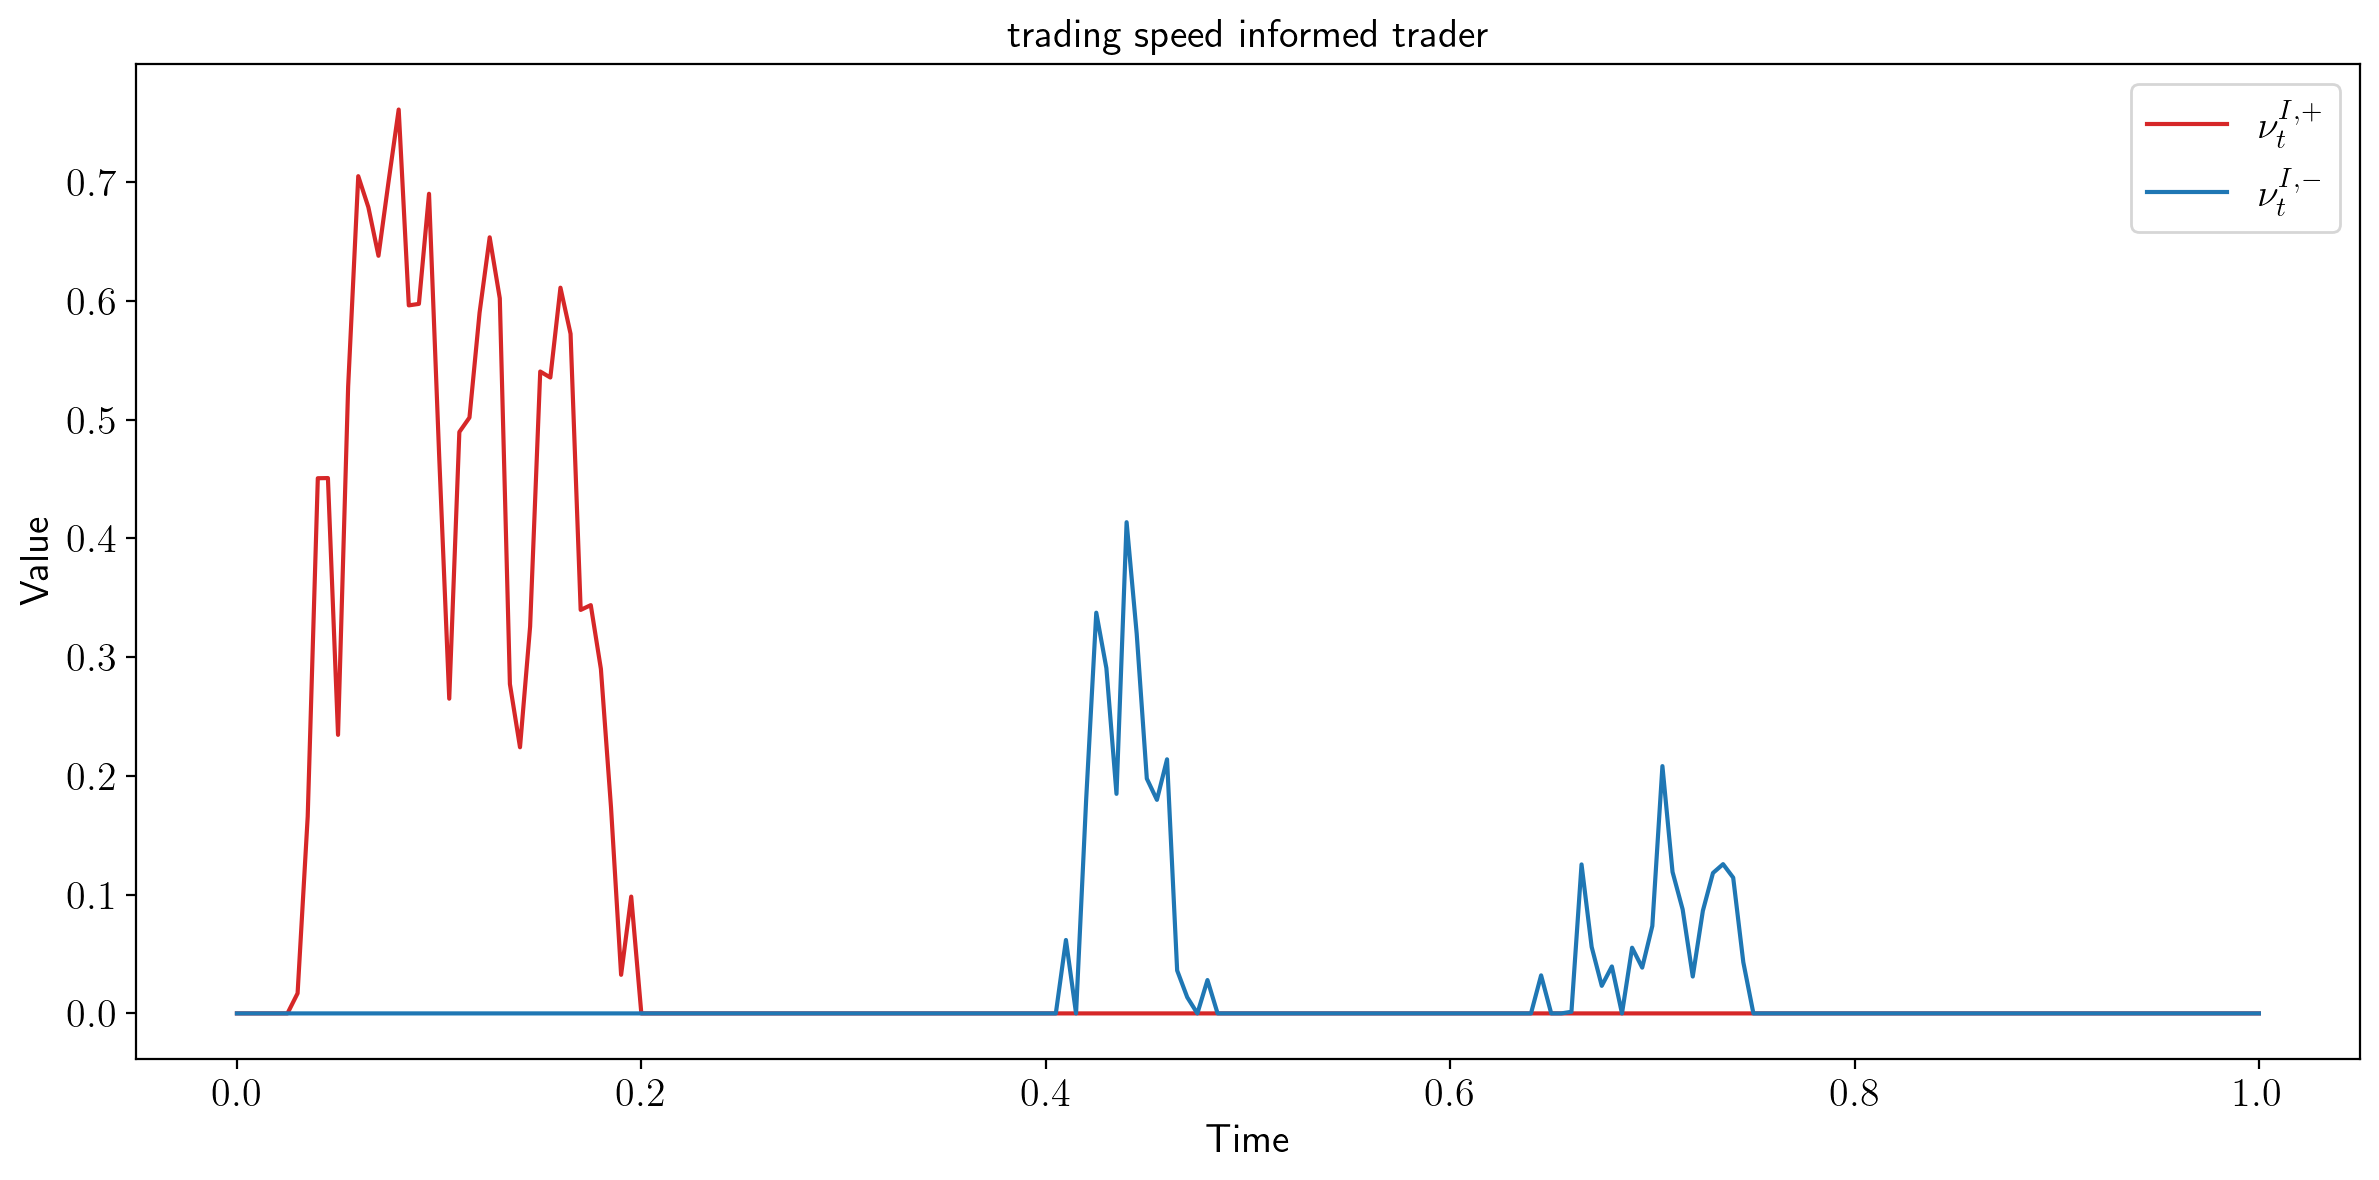

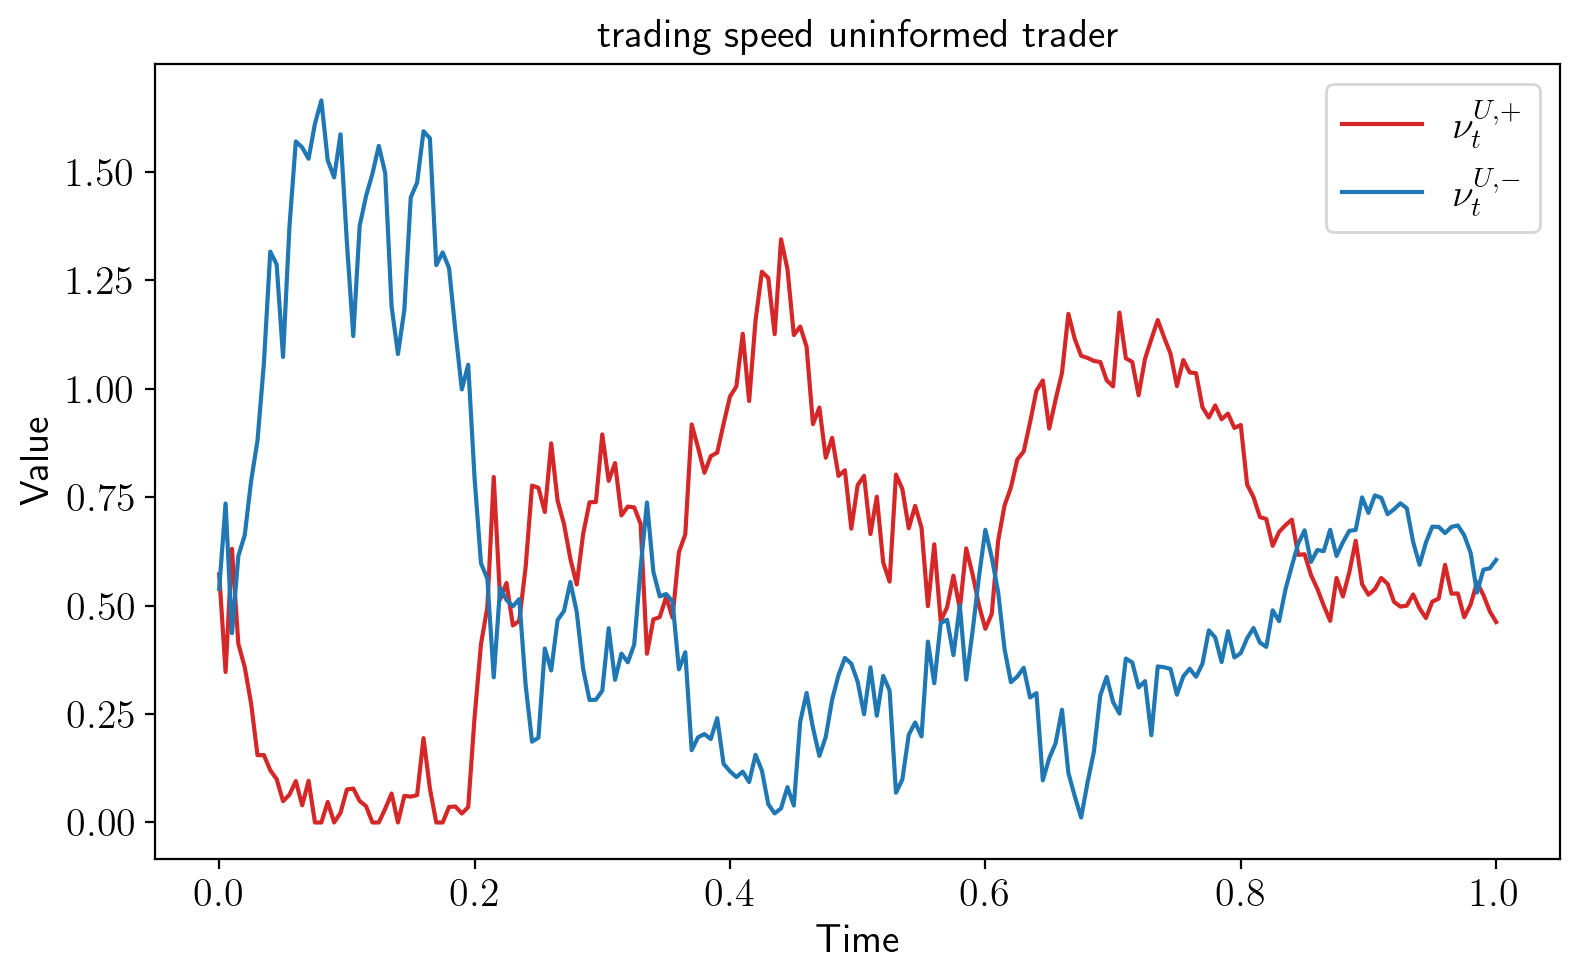

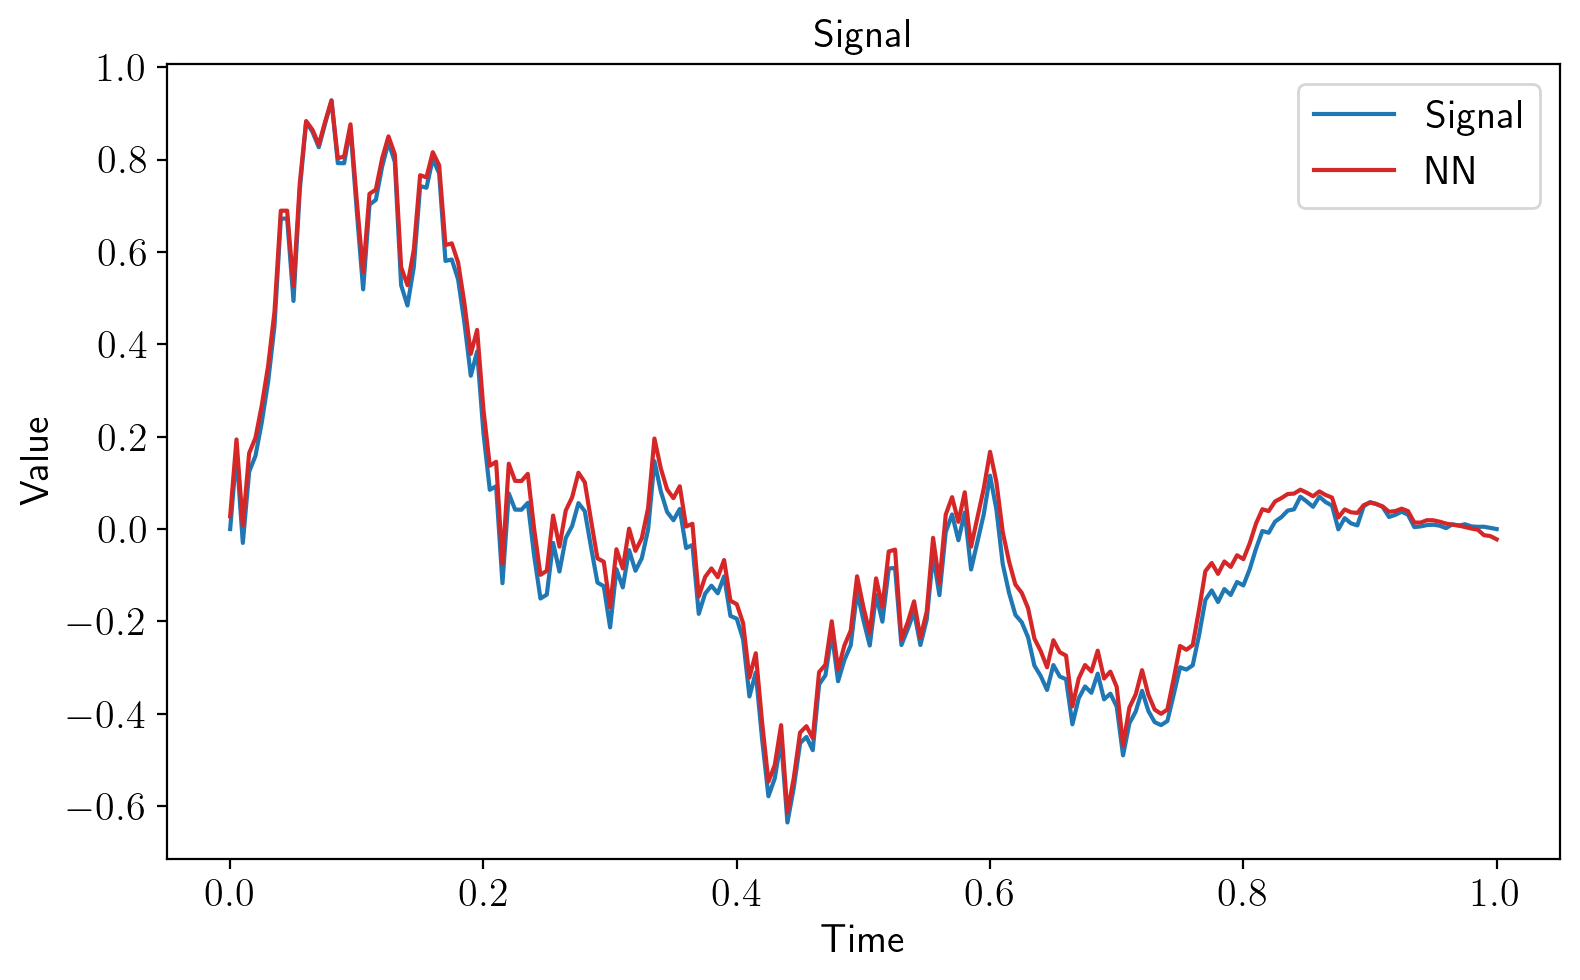

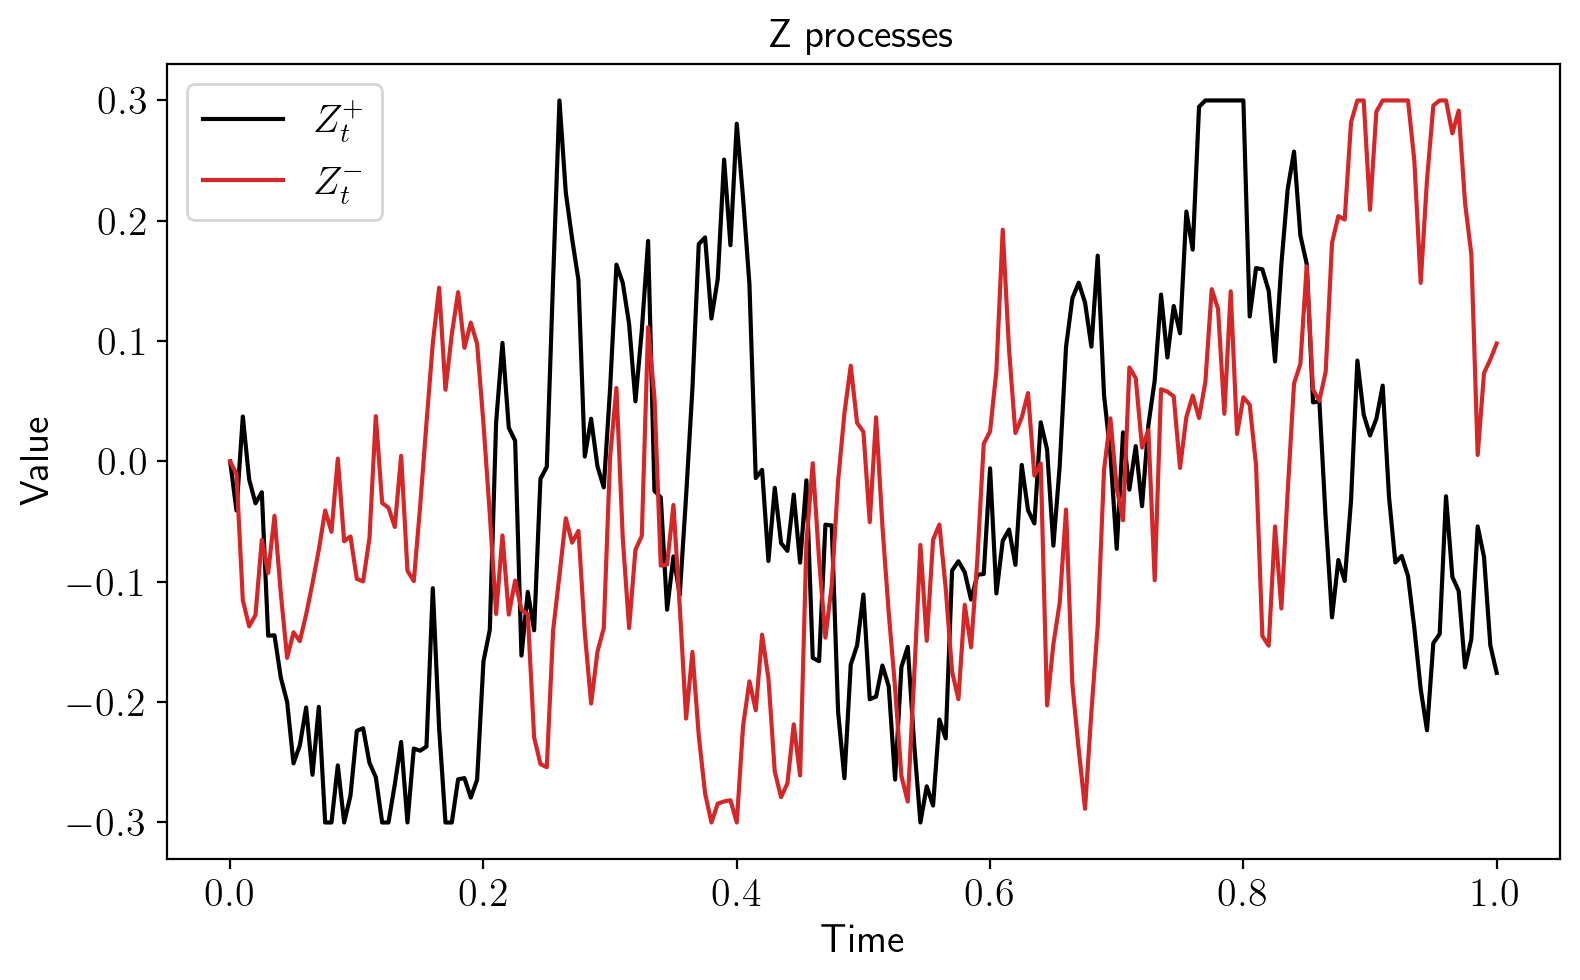

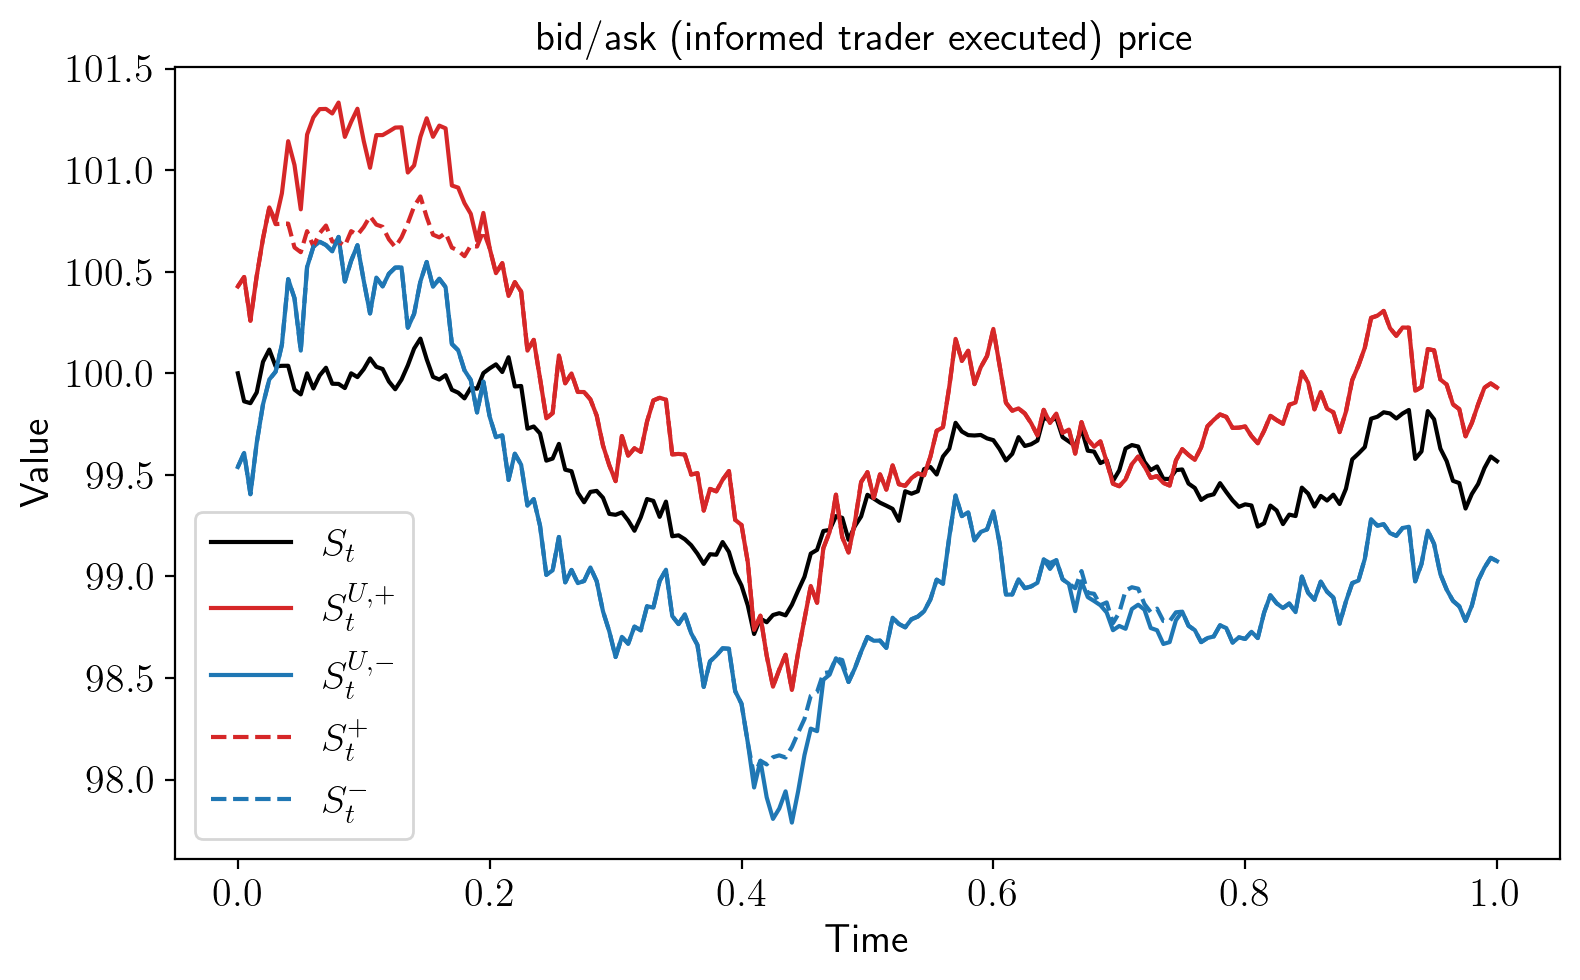

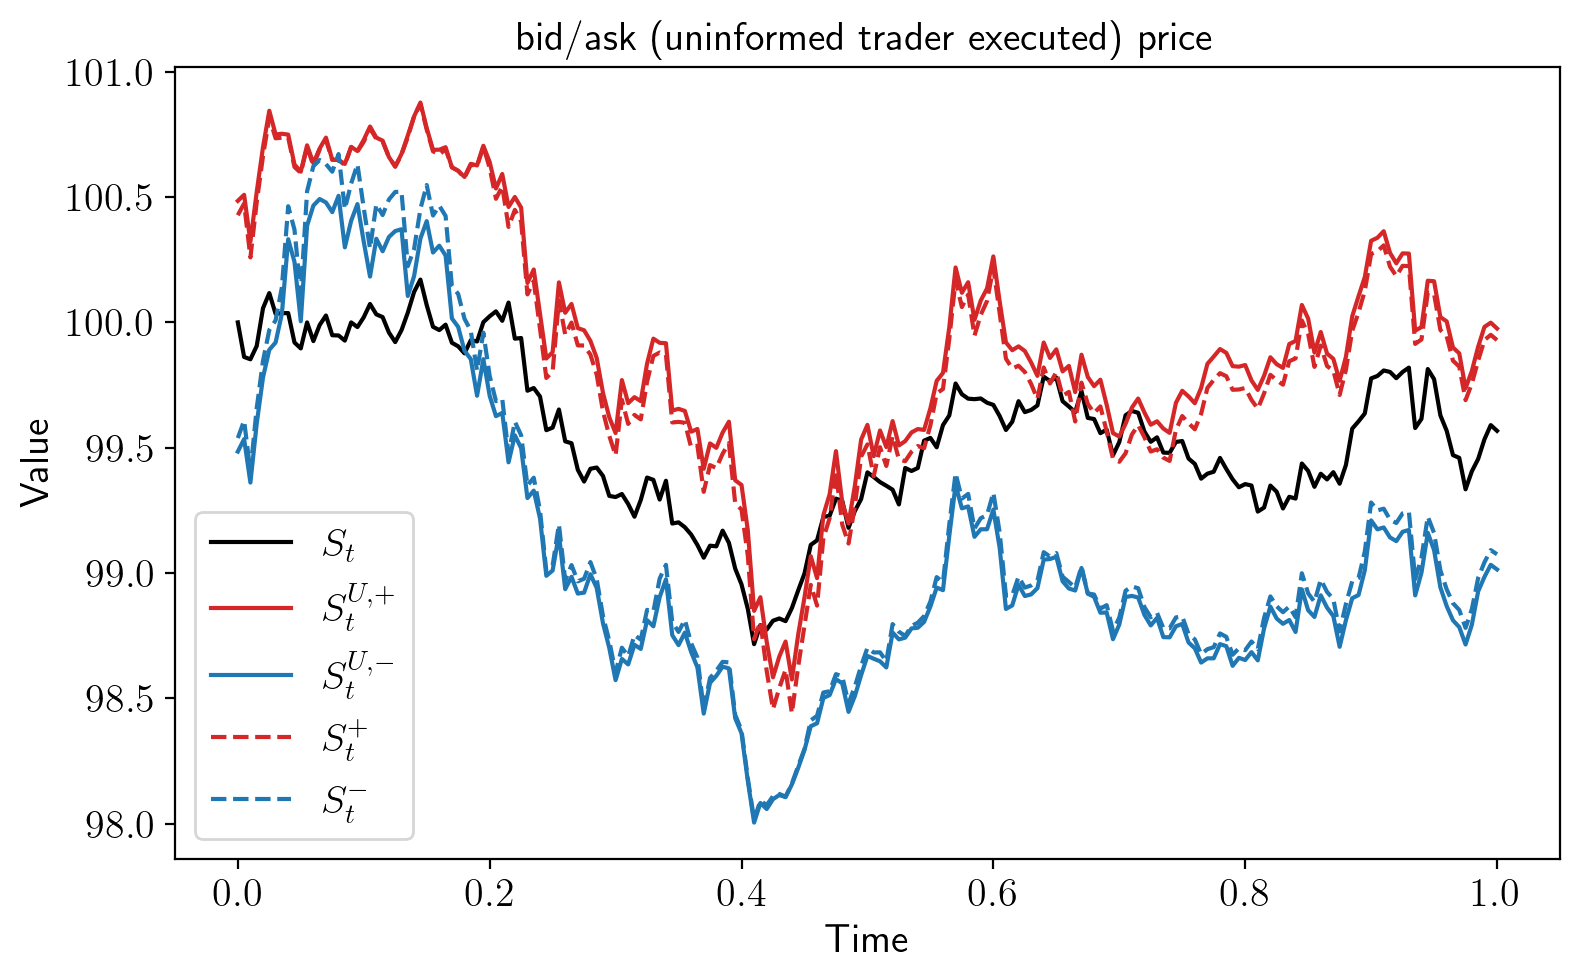

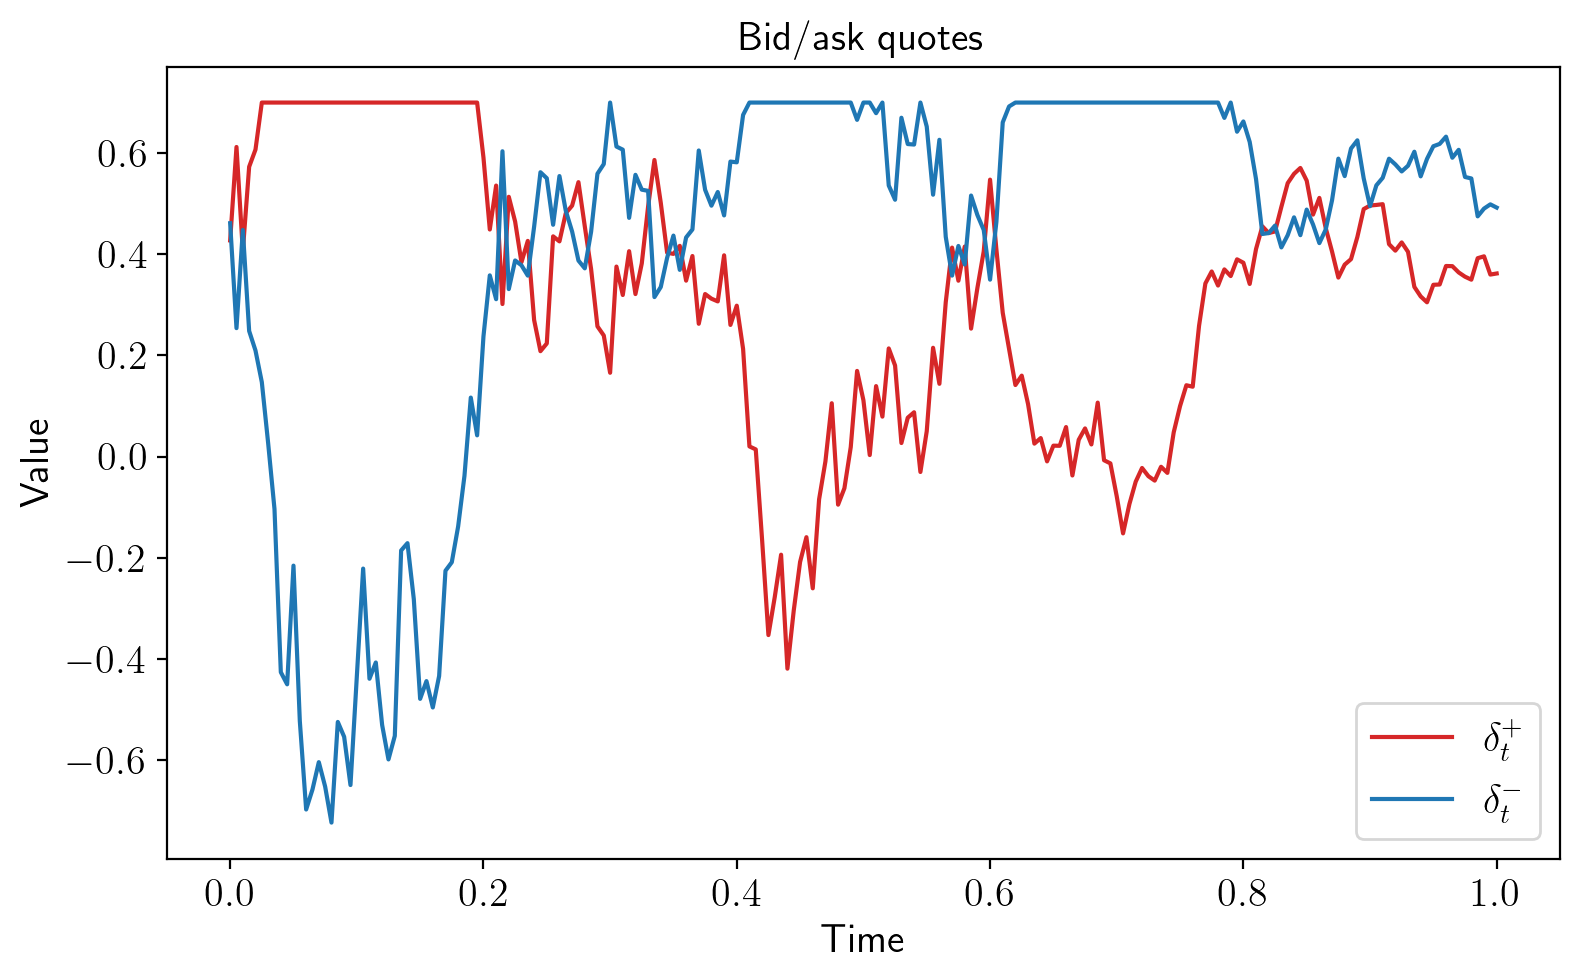

In [113]:
def plot_after_training(sample_size=sample):
    dW_S = torch.randn(sample_size, N, Y0_I.shape[1]) * (T / N) ** 0.5
    dW_A = torch.randn(sample_size, N, Y0_I.shape[1]) * (T / N) ** 0.5
    dW_ZP = torch.randn(sample_size, N, Y0_I.shape[1]) * (T / N) ** 0.5
    dW_ZM = torch.randn(sample_size, N, Y0_I.shape[1]) * (T / N) ** 0.5
    # Récupérer la trajectoire simulée après l'entraînement
    Q_I,Q_B, Y_I,Y_B,_,_,_,_,_,_,_,_,alpha,Z_plus,Z_minus = simulate_trajectory(
            Q0_I.expand(sample_size, -1), Q0_B.expand(sample_size,-1), Y0_I.expand(sample_size, -1), Y0_B.expand(sample_size, -1),Z_nets, b_QI,b_QB,b_YI,b_YB, T, N,  dW_S,dW_A,dW_ZP,dW_ZM)
    # Affichage des courbes pour le premier élément du batch
    plot_trajectory(Q_I, Q_B, Y_I, Y_B,alpha,Z_plus,Z_minus, T, N, dW_S, sample_idx=0,sample_size=sample)

# Appeler la fonction pour afficher les courbes après l'entraînement
plot_after_training()

In [103]:
def PnL(nb_it):

    dW_S = torch.randn(nb_it, N, Y0_I.shape[1]) * (T / N) ** 0.5
    dW_A = torch.randn(nb_it, N, Y0_I.shape[1]) * (T / N) ** 0.5
    dW_ZP = torch.randn(nb_it, N, Y0_I.shape[1]) * (T / N) ** 0.5
    dW_ZM = torch.randn(nb_it, N, Y0_I.shape[1]) * (T / N) ** 0.5
    # Récupérer la trajectoire simulée après l'entraînement
    Q_I,Q_B, Y_I,Y_B,_,_,_,_,_,_,_,_,alpha,Z_plus,Z_minus = simulate_trajectory(
            Q0_I.expand(nb_it, -1), Q0_B.expand(nb_it,-1), Y0_I.expand(nb_it, -1), Y0_B.expand(nb_it, -1),Z_nets, b_QI,b_QB,b_YI,b_YB, T, N,  dW_S,dW_A,dW_ZP,dW_ZM)
    X_I =  Q0_I.expand(nb_it, -1)
    X_U = Q0_I.expand(nb_it, -1)
    S = torch.tensor([100], dtype=torch.float32).expand(nb_it, -1)

    X_B = Q0_B.expand(nb_it, -1)
    Q_tot_I = Q0_I.expand(nb_it, -1)
    Q_tot_B = Q0_B.expand(nb_it, -1)
    spread_vals = Q0_I.expand(nb_it, -1)
    trading_vals = Q0_I.expand(nb_it, -1)


    for t in range(N):
        nu_plus,nu_minus,delta_plus,delta_minus = nu(Y_I[t],Y_B[t],Z_plus[t],Z_minus[t])
        spread_vals = spread_vals+ (delta_plus+delta_minus)*dt
        trading_vals = trading_vals + (nu_plus + nu_minus)*dt


        nu_inf_plus = zeta - k*delta_plus + Z_plus[t]
        nu_inf_minus = zeta - k*delta_minus + Z_minus[t]

        X_I = X_I + (S - delta_minus - kappa_i*nu_minus)*nu_minus*dt - (S + delta_plus + kappa_i*nu_plus)*nu_plus*dt
        X_U = X_U + (S - delta_minus - kappa_u*nu_inf_minus)*nu_inf_minus*dt - (S + delta_plus + kappa_u*nu_inf_plus)*nu_inf_plus*dt
        X_B = (-1)*X_I +(-1)* X_U
        S = S +alpha[t]*dt + sigma_s*dW_S[:,t,:]

        
        Q_tot_I = Q_tot_I + Q_I[t]**2*dt
        Q_tot_B = Q_tot_B + Q_B[t]**2*dt
        
    data_I = (X_I + S*Q_I[-1]- alpha_I*Q_I[-1]**2-phi_I*Q_tot_I).detach().numpy()
    data_B = (X_B + S*Q_B[-1]- alpha_B*Q_B[-1]**2-phi_B*Q_tot_B).detach().numpy()

    val_inv_I =  (S*Q_I[-1]- alpha_I*Q_I[-1]**2).detach().numpy()
    val_inv_B = (S*Q_B[-1]- alpha_B*Q_B[-1]**2).detach().numpy()

    return data_I,data_B,spread_vals,trading_vals,val_inv_I,val_inv_B


In [104]:
with torch.no_grad():
    data_I, data_B, spread, trading, val_I, val_M = PnL(100_000)
val_I = np.array(val_I)
val_M = np.array(val_M)
data_I = np.array(data_I)
data_B = np.array(data_B)
spread = spread.detach().numpy()
trading = trading.detach().numpy()
mean_spread = spread.mean()
mean_trading = trading.mean()
mean_value_I = data_I.mean()
mean_value_B = data_B.mean()
mean_val_I = val_I.mean()
mean_val_M = val_M.mean()

In [109]:
def plot_combined_histograms(pnl_i, pnl_b):
    fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

    # Informed trader
    mean_i = pnl_i.mean()
    axes[0].hist(pnl_i, bins=30, alpha=0.6, color='blue', label='Informed trader')
    axes[0].axvline(mean_i, color='red', linestyle='--', linewidth=2, label='Mean')
    axes[0].set_title(f'Informed trader\nMean = {mean_i:.4f}')
    axes[0].set_xlabel('Adjusted PnL')
    axes[0].set_ylabel('Frequency')
    axes[0].legend()

    # Market maker
    mean_m = pnl_b.mean()
    axes[1].hist(pnl_b, bins=30, alpha=0.6, color='green', label='Market maker')
    axes[1].axvline(mean_m, color='red', linestyle='--', linewidth=2, label='Mean')
    axes[1].set_title(f'Market maker\nMean = {mean_m:.4f}')
    axes[1].set_xlabel('Adjusted PnL')
    axes[1].legend()


    plt.suptitle('Histograms of Adjusted PnL by Trader Type', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [110]:
def plot_combined_histograms_2(trading,spread):
    fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

    mean_spread = spread.mean()
    axes[0].hist(spread, bins=30, alpha=0.6, color='blue', label='integrated spread')
    axes[0].axvline(mean_spread, color='red', linestyle='--', linewidth=2, label='Mean')
    axes[0].set_title(f'spread\nMean = {mean_spread:.4f}')
    axes[0].set_xlabel('Integtrated spread')
    axes[0].set_ylabel('Frequency')
    axes[0].legend()

    mean_trad = trading.mean()
    axes[1].hist(trading, bins=30, alpha=0.6, color='blue', label='integrated trading size')
    axes[1].axvline(mean_trad, color='red', linestyle='--', linewidth=2, label='Mean')
    axes[1].set_title(f'trading size\nMean = {mean_trad:.4f}')
    axes[1].set_xlabel('Integrated trading size')
    axes[1].set_ylabel('Frequency')
    axes[1].legend()
    
    
    plt.suptitle('Histograms of Integrated trading speed of the informed traders, and the spread of the market maker', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    #plt.savefig('figures/spread_trading_size_NN.pdf', dpi=300, format='pdf')
    plt.show()


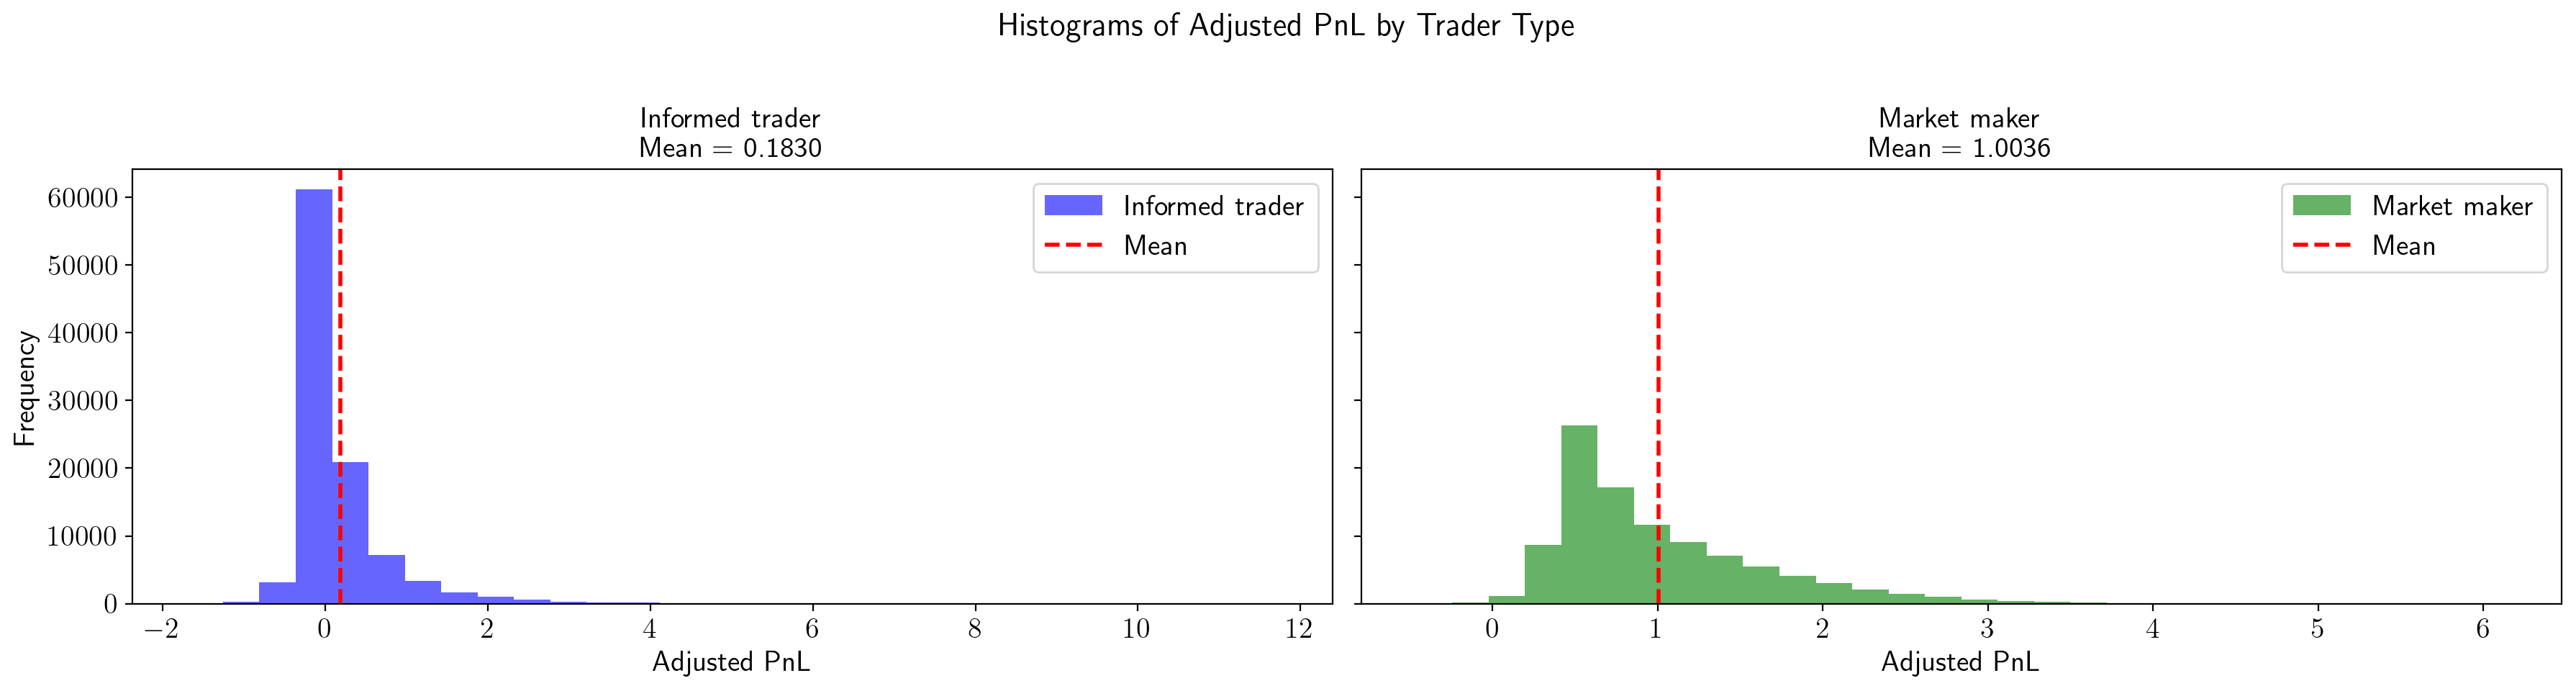

None


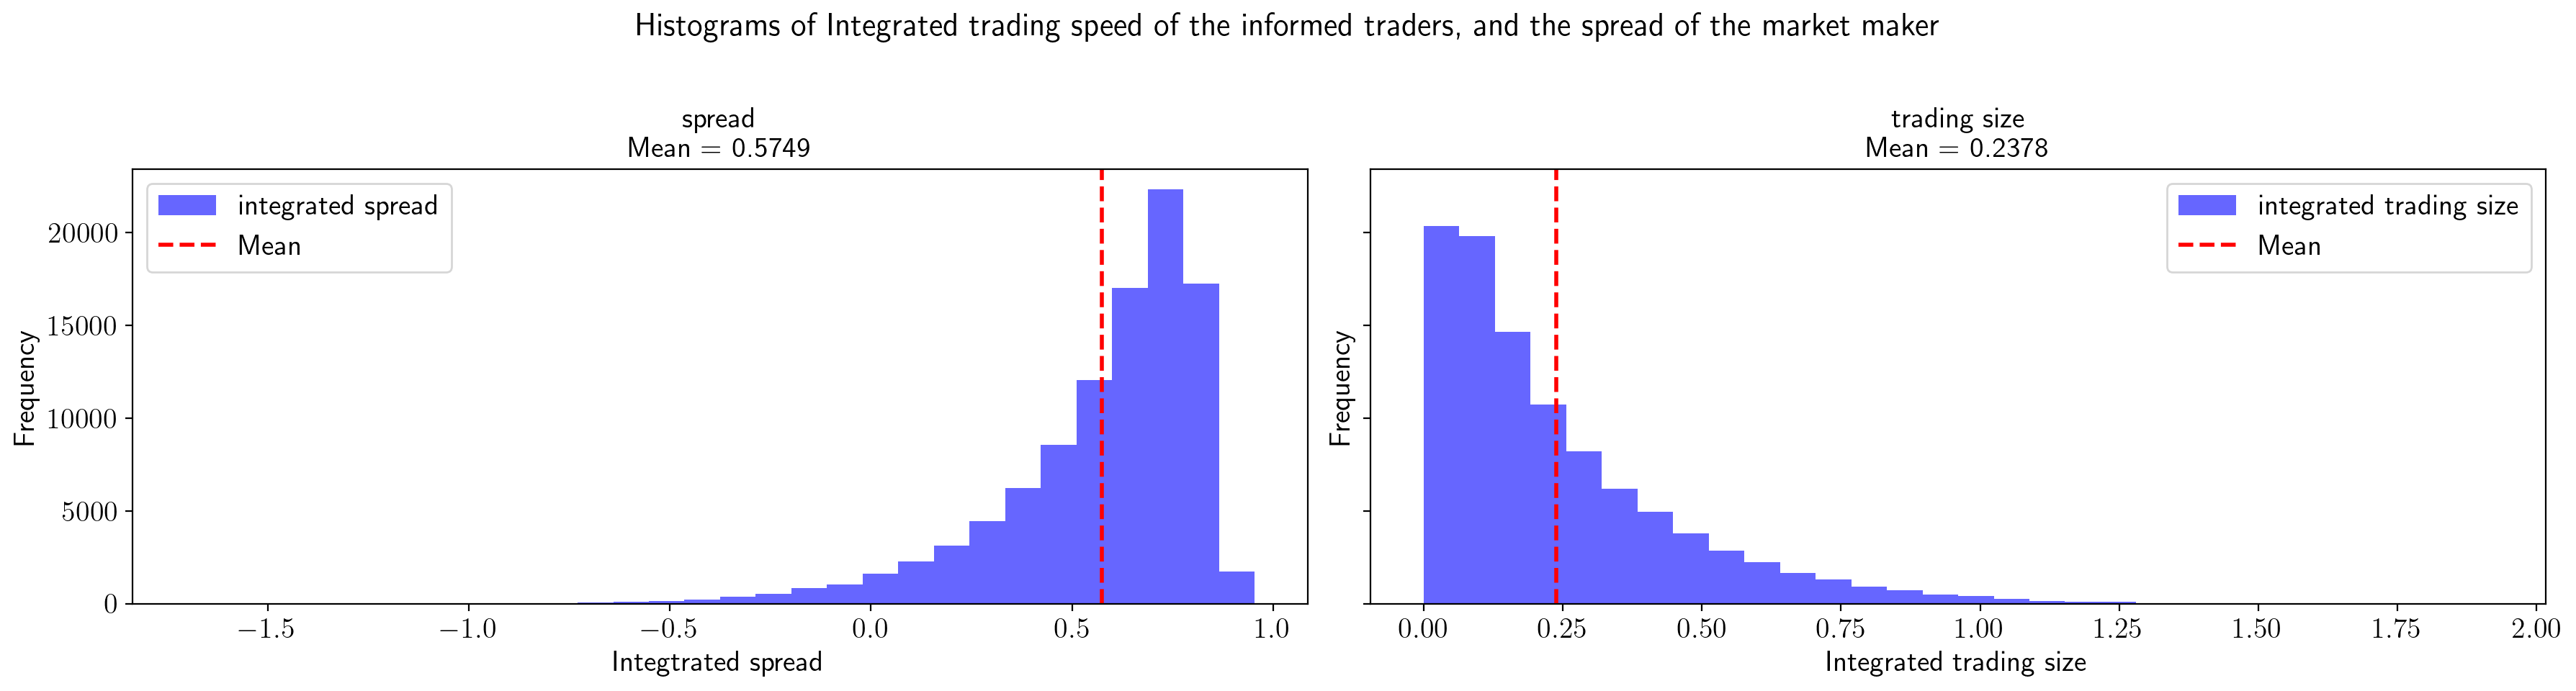

None


In [111]:
print(plot_combined_histograms(data_I,data_B))
print((plot_combined_histograms_2(trading,spread)))